In [2]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")
#df.to_csv("online_retail_utf8.csv", index=False, encoding="utf-8")


In [114]:
df.shape

(541909, 8)

In [115]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [116]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [117]:
df.duplicated().sum()

np.int64(5268)

In [118]:
# returns/cancellations
(df["Quantity"] <= 0).sum()

np.int64(10624)

In [119]:
#Negative/zero price
(df["UnitPrice"] <= 0).sum()

np.int64(2517)

In [120]:
clean_df = df.copy()

In [121]:
# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

In [122]:
# Remove returns/cancellations
clean_df = clean_df[clean_df["Quantity"] > 0]


In [123]:
# Remove invalid prices
clean_df = clean_df[clean_df["UnitPrice"] > 0]

In [124]:
print(clean_df.shape)

(524878, 8)


In [125]:
# Create Revenue column
clean_df["Revenue"] = clean_df["Quantity"] * clean_df["UnitPrice"]

##### Note
I performed data quality checks and removed 5,268 duplicate records, excluded return/cancellation transactions identified by negative quantities, and filtered out non-positive prices. This reduced the dataset from 541,909 to 524,878 valid sales transactions before analysis.

#### KPI

In [126]:
print("Total Revenue:", round(clean_df["Revenue"].sum(),2))

print("Total Orders:",
      clean_df["InvoiceNo"].nunique())

print("Total Customers:",
      clean_df["CustomerID"].nunique())

print("Total Countries:",
      clean_df["Country"].nunique())

Total Revenue: 10642110.8
Total Orders: 19960
Total Customers: 4338
Total Countries: 38


In [127]:
# save clean dataset
clean_df.to_csv("online_retail_cleaned.csv", index=False)

# Revenue Analysis

Questions:

Which month generated highest revenue?
Which month generated lowest revenue?
Is revenue stable?
Are there seasonal peaks?

In [128]:
clean_df["Year"] = clean_df["InvoiceDate"].dt.year
clean_df["Month"] = clean_df["InvoiceDate"].dt.month
clean_df["Month_Name"] = clean_df["InvoiceDate"].dt.month_name()

#### Note
I extracted Year and Month from the transaction date to enable time-series analysis. This allowed me to study revenue trends, identify seasonal patterns, and compare business performance across different periods.

## Monthly Analysis

In [129]:
month_order = [
    "January","February","March","April",
    "May","June","July","August",
    "September","October","November","December"
]

monthly_revenue = (
    clean_df.groupby("Month_Name")["Revenue"]
    .sum()
    .reindex(month_order)
    .reset_index()
)

monthly_revenue

,Month_Name,Revenue
0,January,689811.610
1,February,522545.560
2,March,716215.260
3,April,536968.491
4,May,769296.610
5,June,760547.010
6,July,718076.121
7,August,757841.380
8,September,1056435.192
9,October,1151263.730


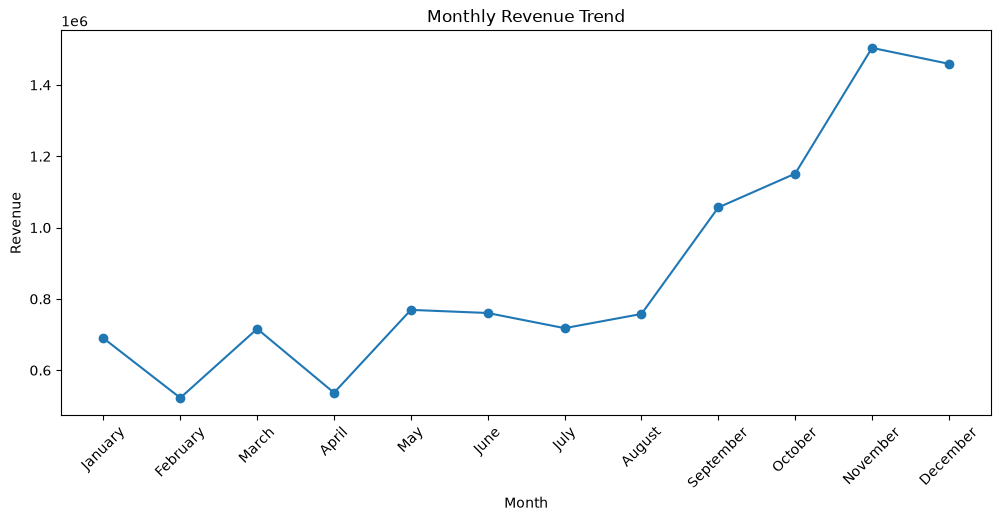

In [130]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(
    monthly_revenue["Month_Name"],
    monthly_revenue["Revenue"],
    marker="o"
)

plt.xticks(rotation=45)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.show()

#### Observation
Revenue remained relatively stable during the first eight months of the year. Starting in September, revenue increased significantly, peaking at approximately £1.5 million in November. This pattern indicates strong seasonality, likely driven by holiday shopping and promotional events. The findings suggest that marketing and inventory planning should be intensified during Q4.


## Top Countries by Revenue

In [76]:
country_revenue = (
    clean_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

country_revenue.head(10)

,Country,Revenue
0,United Kingdom,9001744.094
1,Netherlands,285446.340
2,EIRE,283140.520
3,Germany,228678.400
4,France,209625.370
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,57067.600
8,Belgium,41196.340
9,Sweden,38367.830


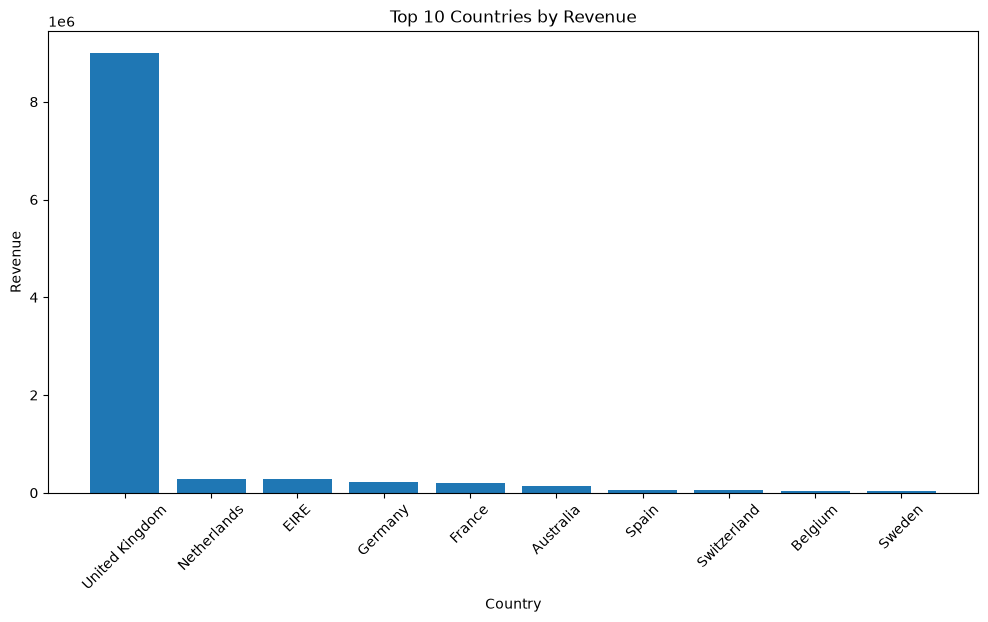

In [77]:
import matplotlib.pyplot as plt

top10 = country_revenue.head(10)

plt.figure(figsize=(12,6))

plt.bar(top10["Country"], top10["Revenue"])

plt.xticks(rotation=45)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")

plt.show()

#### observation
Approximately 85% of total revenue is generated from the United Kingdom, indicating significant geographic concentration risk. Any economic downturn, change in customer demand, or competitive pressure in the UK market could have a substantial impact on overall business performance. To reduce dependency, the company should focus on expanding high-potential international markets such as the Netherlands, Germany, France, and EIRE.

## Top Products Analysis

In [78]:
product_revenue = (
    clean_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

product_revenue.head(10)

,Description,Revenue
0,DOTCOM POSTAGE,206248.77
1,REGENCY CAKESTAND 3 TIER,174156.54
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
4,PARTY BUNTING,99445.23
5,JUMBO BAG RED RETROSPOT,94159.81
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POSTAGE,78101.88
8,Manual,77752.82
9,RABBIT NIGHT LIGHT,66870.03


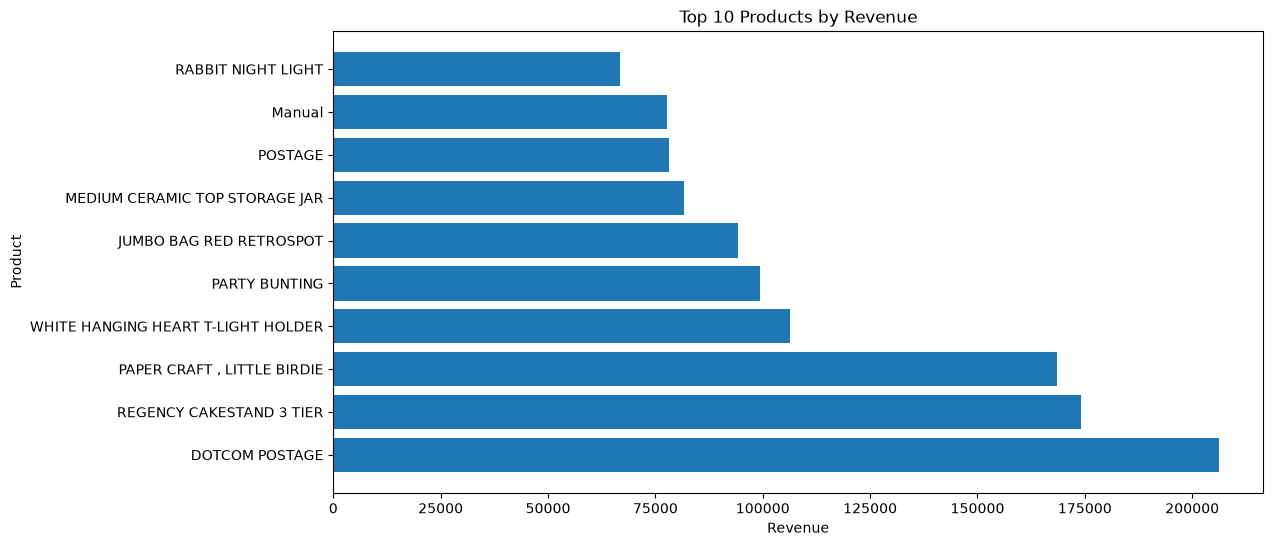

In [79]:
import matplotlib.pyplot as plt

top10_products = product_revenue.head(10)

plt.figure(figsize=(12,6))

plt.barh(
    top10_products["Description"],
    top10_products["Revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.show()

### Obsevation
Initially, shipping-related entries such as DOTCOM POSTAGE appeared as top revenue contributors. After recognizing that these were service charges rather than products, I focused on actual merchandise and identified REGENCY CAKESTAND 3 TIER as the highest-revenue product. This highlighted the importance of validating business context rather than relying solely on raw rankings.

* Product revenue analysis revealed that revenue is concentrated among a relatively small number of products. After excluding non-product entries such as postage and manual charges, REGENCY CAKESTAND 3 TIER emerged as the highest revenue-generating product. Additionally, several top-performing items belonged to the home décor category, indicating a strong customer preference for decorative and gift products.

### Average Order Value (AOV)

In [80]:
aov = clean_df["Revenue"].sum() / clean_df["InvoiceNo"].nunique()

print("Average Order Value =", round(aov,2))

Average Order Value = 533.17


# Customer Intelligence Analysis

##### Who generates the revenue?

### Top Customers by Revenue

In [81]:
customer_revenue = (
    clean_df.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

customer_revenue.head(10)

,CustomerID,Revenue
0,14646.0,280206.02
1,18102.0,259657.30
2,17450.0,194390.79
3,16446.0,168472.50
4,14911.0,143711.17
5,12415.0,124914.53
6,14156.0,117210.08
7,17511.0,91062.38
8,16029.0,80850.84
9,12346.0,77183.60


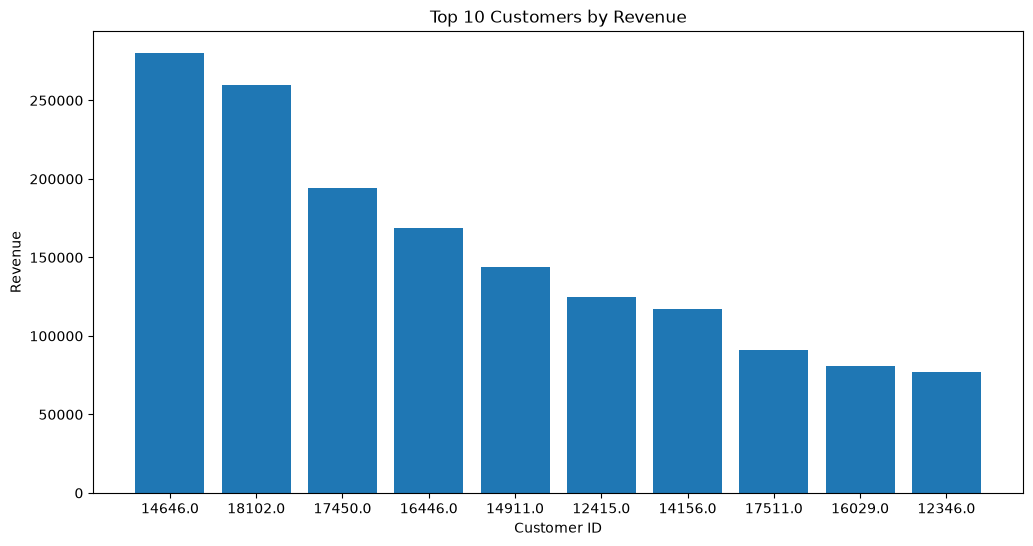

In [82]:


top10_customers = customer_revenue.head(10)

plt.figure(figsize=(12,6))

plt.bar(
    top10_customers["CustomerID"].astype(str),
    top10_customers["Revenue"]
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue")

plt.show()

#### Observation
The analysis showed that revenue is concentrated among a group of high-value customers rather than a single customer. The top customer generated approximately £280K in revenue, indicating the importance of customer retention and loyalty strategies for maintaining business performance.

#### Customer Concentration Risk

In [83]:
top_customer = customer_revenue.iloc[0]["Revenue"]

total_revenue = clean_df["Revenue"].sum()

contribution = (top_customer / total_revenue) * 100

print(round(contribution,2))

2.63


##### Observation
The highest-value customer contributed approximately 2.63% of total revenue. This indicates that revenue is relatively diversified across customers, reducing dependence on any single customer and lowering customer concentration risk.

## Customer Purchase Frequency

In [84]:
customer_frequency = (
    clean_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index()
)

customer_frequency.head(10)

,CustomerID,InvoiceNo
0,12748.0,209
1,14911.0,201
2,17841.0,124
3,13089.0,97
4,14606.0,93
5,15311.0,91
6,12971.0,86
7,14646.0,73
8,16029.0,63
9,13408.0,62


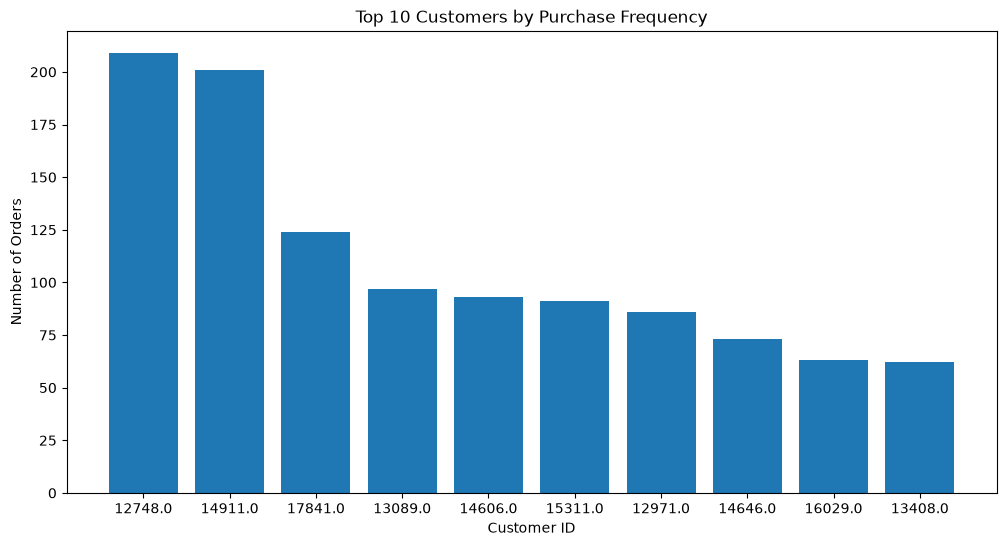

In [85]:
top10_freq = customer_frequency.head(10)

plt.figure(figsize=(12,6))

plt.bar(
    top10_freq["CustomerID"].astype(str),
    top10_freq["InvoiceNo"]
)

plt.title("Top 10 Customers by Purchase Frequency")
plt.xlabel("Customer ID")
plt.ylabel("Number of Orders")

plt.show()

##### Observation
Customer frequency analysis showed that the most frequent buyers were not necessarily the highest revenue-generating customers. This indicates different customer purchasing behaviors and highlights the need for separate retention and revenue-growth strategies for different customer segments.

## Repeat vs One-Time Customer Analysis

In [86]:
customer_orders = (
    clean_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

one_time = (customer_orders == 1).sum()
repeat = (customer_orders > 1).sum()

print("One-Time Customers:", one_time)
print("Repeat Customers:", repeat)

One-Time Customers: 1493
Repeat Customers: 2845


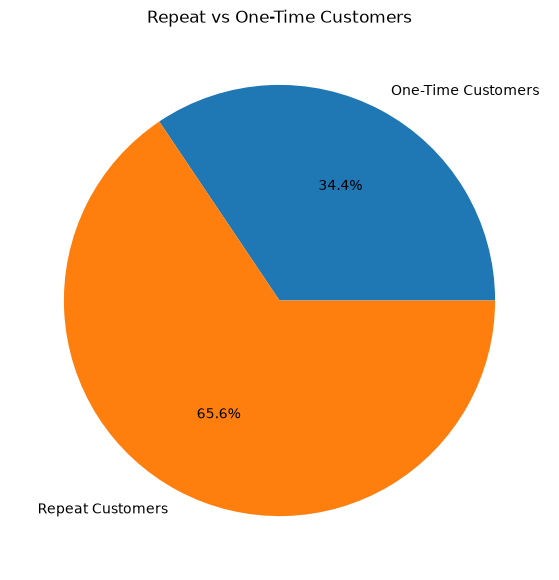

In [87]:
import matplotlib.pyplot as plt

labels = ["One-Time Customers", "Repeat Customers"]
sizes = [1493, 2845]

plt.figure(figsize=(7,7))

plt.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%"
)

plt.title("Repeat vs One-Time Customers")

plt.show()

#### Observation
Approximately 66% of customers made multiple purchases, while 34% purchased only once. This indicates strong customer retention and suggests that the business has a loyal customer base that contributes to recurring revenue.

## Revenue from Repeat vs One-Time Customers

In [88]:
customer_orders = (
    clean_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

one_time_customers = customer_orders[customer_orders == 1].index
repeat_customers = customer_orders[customer_orders > 1].index

one_time_revenue = clean_df[
    clean_df["CustomerID"].isin(one_time_customers)
]["Revenue"].sum()

repeat_revenue = clean_df[
    clean_df["CustomerID"].isin(repeat_customers)
]["Revenue"].sum()

print("One-Time Revenue:", round(one_time_revenue,2))
print("Repeat Revenue:", round(repeat_revenue,2))

One-Time Revenue: 613989.56
Repeat Revenue: 8273219.33


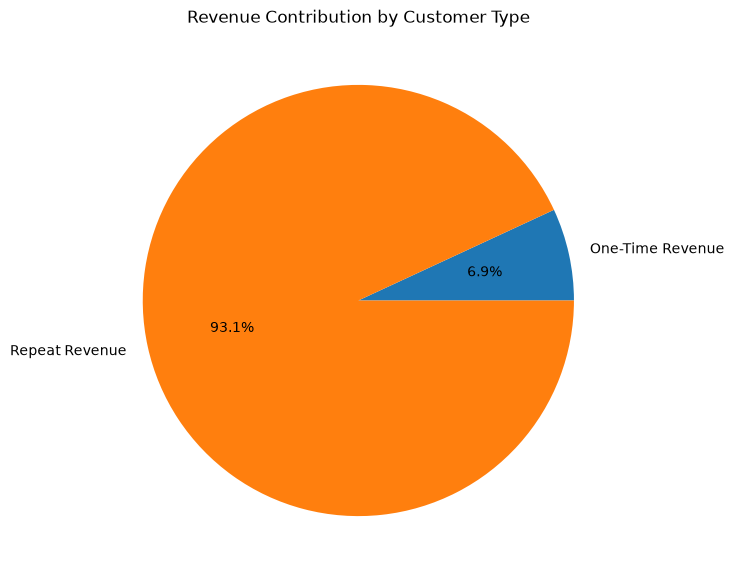

In [89]:
labels = ["One-Time Revenue", "Repeat Revenue"]
values = [613989.56, 8273219.33]

plt.figure(figsize=(7,7))

plt.pie(
    values,
    labels=labels,
    autopct="%1.1f%%"
)

plt.title("Revenue Contribution by Customer Type")

plt.show()

One-time customers → ~6% revenue
Repeat customers → ~78% revenue
remaining revenue difference comes from records without CustomerID

#### Observation
While repeat customers represented approximately 66% of the customer base, they generated nearly 78% of total revenue. This demonstrates that customer retention is a key driver of business performance and highlights the importance of loyalty-focused strategies.

# RFM Analysis (Recency, Frequency, Monetary)

Recency Analysis
How recently did a customer purchase?

Frequency Analysis
How often does a customer purchase?


Monetary Analysis
How much money has a customer spent?

## Recency Analysis

In [90]:


snapshot_date = clean_df["InvoiceDate"].max() + pd.Timedelta(days=1)

recency_df = (
    clean_df.groupby("CustomerID")["InvoiceDate"]
    .max()
    .reset_index()
)

recency_df["Recency"] = (
    snapshot_date - recency_df["InvoiceDate"]
).dt.days

recency_df.head()

,CustomerID,InvoiceDate,Recency
0,12346.0,2011-01-18 10:01:00,326
1,12347.0,2011-12-07 15:52:00,2
2,12348.0,2011-09-25 13:13:00,75
3,12349.0,2011-11-21 09:51:00,19
4,12350.0,2011-02-02 16:01:00,310


#### Observation 
I calculated Recency by measuring the number of days since each customer's last purchase. Customers with lower Recency values were considered more engaged, while customers with higher Recency values were identified as potential churn risks.

## Frequency Metric

In [91]:
frequency_df = (
    clean_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .reset_index()
)

frequency_df.columns = ["CustomerID", "Frequency"]

frequency_df.head()

,CustomerID,Frequency
0,12346.0,1
1,12347.0,7
2,12348.0,4
3,12349.0,1
4,12350.0,1


#### Observation
I calculated Frequency by counting unique invoices for each customer. This metric helped identify loyal customers who purchase repeatedly and provided insights into customer engagement and retention.

## Monetary Metric

In [92]:
monetary_df = (
    clean_df.groupby("CustomerID")["Revenue"]
    .sum()
    .reset_index()
)

monetary_df.columns = ["CustomerID", "Monetary"]

monetary_df.head()

,CustomerID,Monetary
0,12346.0,77183.60
1,12347.0,4310.00
2,12348.0,1797.24
3,12349.0,1757.55
4,12350.0,334.40


#### Observation
I calculated Monetary value by summing total revenue generated by each customer. This metric helped identify high-value customers and measure the overall financial contribution of each customer to the business

## RFM Table

In [93]:
rfm = recency_df.merge(
    frequency_df,
    on="CustomerID"
)

rfm = rfm.merge(
    monetary_df,
    on="CustomerID"
)

rfm.head()

,CustomerID,InvoiceDate,Recency,Frequency,Monetary
0,12346.0,2011-01-18 10:01:00,326,1,77183.60
1,12347.0,2011-12-07 15:52:00,2,7,4310.00
2,12348.0,2011-09-25 13:13:00,75,4,1797.24
3,12349.0,2011-11-21 09:51:00,19,1,1757.55
4,12350.0,2011-02-02 16:01:00,310,1,334.40


#### Observation
I combined Recency, Frequency, and Monetary metrics into a unified RFM table. This allowed me to evaluate customer value from multiple dimensions rather than relying on a single metric and formed the basis for customer segmentation.

## RFM Scoring

In [94]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5,4,3,2,1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1,2,3,4,5]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    5,
    labels=[1,2,3,4,5]
)

rfm.head()

,CustomerID,InvoiceDate,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346.0,2011-01-18 10:01:00,326,1,77183.60,1,1,5
1,12347.0,2011-12-07 15:52:00,2,7,4310.00,5,5,5
2,12348.0,2011-09-25 13:13:00,75,4,1797.24,2,4,4
3,12349.0,2011-11-21 09:51:00,19,1,1757.55,4,1,4
4,12350.0,2011-02-02 16:01:00,310,1,334.40,1,1,2


#### Observation
RFM scoring converted customer behavior into standardized scores ranging from 1 to 5. Customers with high scores across all three dimensions were classified as highly valuable, while customers with low scores represented lower engagement and revenue contribution.

In [95]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

rfm[[
    "CustomerID",
    "R_Score",
    "F_Score",
    "M_Score",
    "RFM_Score"
]].head(10)

,CustomerID,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,1,1,5,115
1,12347.0,5,5,5,555
2,12348.0,2,4,4,244
3,12349.0,4,1,4,414
4,12350.0,1,1,2,112
5,12352.0,3,5,5,355
6,12353.0,1,1,1,111
7,12354.0,1,1,4,114
8,12355.0,1,1,2,112
9,12356.0,4,3,5,435


##### Note
I combined the Recency, Frequency, and Monetary scores into a single RFM score. This simplified customer evaluation and served as the foundation for customer segmentation. Using the RFM score, customers can be grouped into categories such as Champions, Loyal Customers, and At-Risk Customers for targeted business strategies.

## Customer Segmentation

In [96]:
def segment_customer(row):

    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champion"

    elif row["R_Score"] >= 3 and row["F_Score"] >= 4:
        return "Loyal Customer"

    elif row["M_Score"] >= 4:
        return "Big Spender"

    elif row["R_Score"] <= 2:
        return "At Risk"

    else:
        return "Regular Customer"


rfm["Segment"] = rfm.apply(segment_customer, axis=1)

rfm.head()

,CustomerID,InvoiceDate,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346.0,2011-01-18 10:01:00,326,1,77183.60,1,1,5,115,Big Spender
1,12347.0,2011-12-07 15:52:00,2,7,4310.00,5,5,5,555,Champion
2,12348.0,2011-09-25 13:13:00,75,4,1797.24,2,4,4,244,Big Spender
3,12349.0,2011-11-21 09:51:00,19,1,1757.55,4,1,4,414,Big Spender
4,12350.0,2011-02-02 16:01:00,310,1,334.40,1,1,2,112,At Risk


In [97]:
rfm["Segment"].value_counts()

Segment
At Risk             1371
Regular Customer     964
Champion             957
Big Spender          543
Loyal Customer       503
Name: count, dtype: int64

##### Note
After calculating RFM scores, I segmented customers into five groups. The largest group was At Risk (1,371 customers), indicating an opportunity for customer retention campaigns. The business also had 957 Champion customers and 503 Loyal Customers, providing a strong base for long-term revenue growth through loyalty programs.

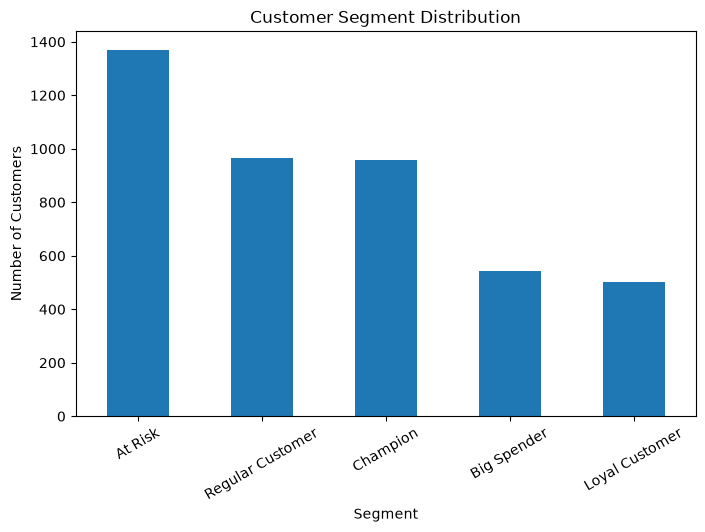

In [98]:
segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(8,5))
segment_counts.plot(kind="bar")

plt.title("Customer Segment Distribution")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30)

plt.show()

#### Observation
The largest segment is At Risk, indicating that customer retention should be a priority. The company also has a healthy number of Champion customers, which should be protected through loyalty programs. Regular Customers represent a significant opportunity because targeted engagement strategies may increase their purchase frequency and spending, allowing some of them to move into higher-value customer segments over time.

In [99]:
customer_segment = rfm[["CustomerID", "Segment"]]

segment_revenue = clean_df.merge(
    customer_segment,
    on="CustomerID"
)

segment_revenue = (
    segment_revenue.groupby("Segment")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

segment_revenue

,Segment,Revenue
0,Champion,5791640.740
1,Big Spender,1339705.881
2,Loyal Customer,895651.561
3,At Risk,487709.562
4,Regular Customer,372501.150


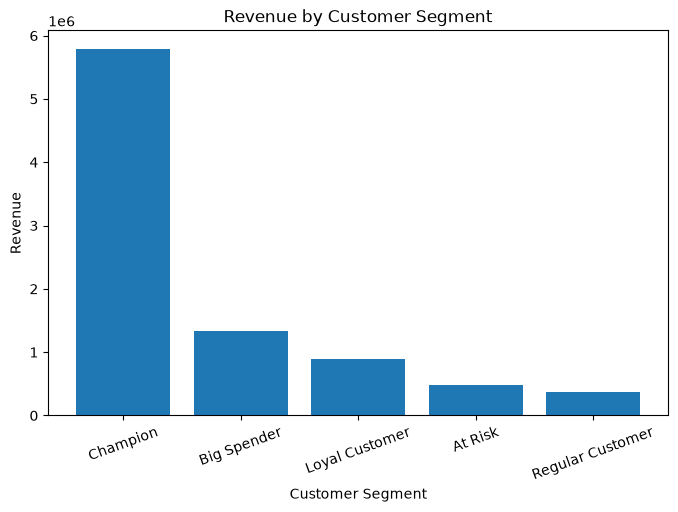

In [100]:
plt.figure(figsize=(8,5))

plt.bar(segment_revenue["Segment"],
        segment_revenue["Revenue"])

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue")

plt.xticks(rotation=20)

plt.show()

#### Observation
I analyzed revenue contribution by customer segment after performing RFM segmentation. Champion customers generated the highest revenue, followed by Big Spenders and Loyal Customers. Although At Risk customers contributed less revenue than these groups, they still represented a meaningful revenue source, making customer retention an important business priority. Based on these findings, I recommended different marketing strategies for each segment to maximize revenue and improve customer retention.

# Cohort Analysis

In [101]:
clean_df["InvoiceMonth"] = clean_df["InvoiceDate"].dt.to_period("M")

In [102]:
clean_df["CohortMonth"] = (
    clean_df.groupby("CustomerID")["InvoiceMonth"]
    .transform("min")
)
clean_df[
    ["CustomerID","InvoiceDate","InvoiceMonth","CohortMonth"]
].head(15)

,CustomerID,InvoiceDate,InvoiceMonth,CohortMonth
0,17850.0,2010-12-01 08:26:00,2010-12,2010-12
1,17850.0,2010-12-01 08:26:00,2010-12,2010-12
2,17850.0,2010-12-01 08:26:00,2010-12,2010-12
3,17850.0,2010-12-01 08:26:00,2010-12,2010-12
4,17850.0,2010-12-01 08:26:00,2010-12,2010-12
5,17850.0,2010-12-01 08:26:00,2010-12,2010-12
6,17850.0,2010-12-01 08:26:00,2010-12,2010-12
7,17850.0,2010-12-01 08:28:00,2010-12,2010-12
8,17850.0,2010-12-01 08:28:00,2010-12,2010-12
9,13047.0,2010-12-01 08:34:00,2010-12,2010-12


## Cohort Index

In [103]:
invoice_year = clean_df["InvoiceMonth"].dt.year
cohort_year = clean_df["CohortMonth"].dt.year

invoice_month = clean_df["InvoiceMonth"].dt.month
cohort_month = clean_df["CohortMonth"].dt.month

clean_df["CohortIndex"] = (
    (invoice_year - cohort_year) * 12
    + (invoice_month - cohort_month)
    + 1
)

In [104]:
clean_df[
    [
        "CustomerID",
        "InvoiceMonth",
        "CohortMonth",
        "CohortIndex"
    ]
].head(20)

,CustomerID,InvoiceMonth,CohortMonth,CohortIndex
0,17850.0,2010-12,2010-12,1
1,17850.0,2010-12,2010-12,1
2,17850.0,2010-12,2010-12,1
3,17850.0,2010-12,2010-12,1
4,17850.0,2010-12,2010-12,1
5,17850.0,2010-12,2010-12,1
6,17850.0,2010-12,2010-12,1
7,17850.0,2010-12,2010-12,1
8,17850.0,2010-12,2010-12,1
9,13047.0,2010-12,2010-12,1


In [105]:
clean_df[clean_df["CohortIndex"] > 1][
    ["CustomerID", "InvoiceMonth", "CohortMonth", "CohortIndex"]
].head(10)

,CustomerID,InvoiceMonth,CohortMonth,CohortIndex
1443,NaN,2010-12,NaT,24146
1444,NaN,2010-12,NaT,24146
1445,NaN,2010-12,NaT,24146
1446,NaN,2010-12,NaT,24146
1447,NaN,2010-12,NaT,24146
1448,NaN,2010-12,NaT,24146
1449,NaN,2010-12,NaT,24146
1450,NaN,2010-12,NaT,24146
1451,NaN,2010-12,NaT,24146
1452,NaN,2010-12,NaT,24146


#### This tells us these rows have missing CustomerID, so they cannot belong to any customer cohort.

##### IMP Note
so if no customerid then we can't determine 
* First purchase month
* Cohort month
* Customer journey
So those rows must not be included.

### handle it 

In [106]:
cohort_df = clean_df.dropna(subset=["CustomerID"]).copy()

In [107]:
cohort_df["InvoiceMonth"] = cohort_df["InvoiceDate"].dt.to_period("M")

cohort_df["CohortMonth"] = (
    cohort_df.groupby("CustomerID")["InvoiceMonth"]
    .transform("min")
)

invoice_year = cohort_df["InvoiceMonth"].dt.year
cohort_year = cohort_df["CohortMonth"].dt.year

invoice_month = cohort_df["InvoiceMonth"].dt.month
cohort_month = cohort_df["CohortMonth"].dt.month

cohort_df["CohortIndex"] = (
    (invoice_year - cohort_year) * 12
    + (invoice_month - cohort_month)
    + 1
)

In [108]:
cohort_df[cohort_df["CohortIndex"] > 1][
    ["CustomerID", "InvoiceMonth", "CohortMonth", "CohortIndex"]
].head(10)

,CustomerID,InvoiceMonth,CohortMonth,CohortIndex
42505,18097.0,2011-01,2010-12,2
42506,18097.0,2011-01,2010-12,2
42507,18097.0,2011-01,2010-12,2
42508,18097.0,2011-01,2010-12,2
42509,18097.0,2011-01,2010-12,2
42510,18097.0,2011-01,2010-12,2
42511,18097.0,2011-01,2010-12,2
42512,18097.0,2011-01,2010-12,2
42513,18097.0,2011-01,2010-12,2
42514,16656.0,2011-01,2010-12,2


#### Observation
I created a Cohort Index to represent the number of months since each customer's first purchase. This standardized the customer timeline and enabled cohort-based retention analysis.

## Retention Matrix

##### Out of all customers who joined in a particular month, how many returned in the following months

In [109]:
cohort_counts = (
    cohort_df.groupby(["CohortMonth", "CohortIndex"])["CustomerID"]
    .nunique()
    .reset_index()
)

cohort_counts.head()

,CohortMonth,CohortIndex,CustomerID
0,2010-12,1,885
1,2010-12,2,324
2,2010-12,3,286
3,2010-12,4,340
4,2010-12,5,321


I grouped the data by Cohort Month and Cohort Index, then counted unique customers using nunique(). This allowed me to measure how many customers from each cohort remained active over time.

In [110]:
retention_matrix = cohort_counts.pivot(
    index="CohortMonth",
    columns="CohortIndex",
    values="CustomerID"
)

retention_matrix

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,885.0,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0,235.0
2011-01,417.0,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0,NaN
2011-02,380.0,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN,NaN
2011-03,452.0,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN,NaN
2011-04,300.0,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,188.0,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The matrix shows that customer purchasing is not continuous every month. Instead, many customers buy intermittently. This means businesses should not assume a customer is lost simply because they skipped one month. Re-engagement campaigns can still bring them back.

## Retention Percentage Matrix

In [111]:
retention = retention_matrix.divide(
    retention_matrix[1],
    axis=0
)

retention = retention.round(3)

retention.head()

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,1.0,0.366,0.323,0.384,0.363,0.398,0.363,0.349,0.354,0.395,0.374,0.503,0.266
2011-01,1.0,0.221,0.266,0.230,0.321,0.288,0.247,0.242,0.300,0.326,0.365,0.118,NaN
2011-02,1.0,0.187,0.187,0.284,0.271,0.247,0.253,0.279,0.247,0.305,0.068,NaN,NaN
2011-03,1.0,0.150,0.252,0.199,0.223,0.168,0.268,0.230,0.279,0.086,NaN,NaN,NaN
2011-04,1.0,0.213,0.203,0.210,0.197,0.227,0.217,0.260,0.073,NaN,NaN,NaN,NaN


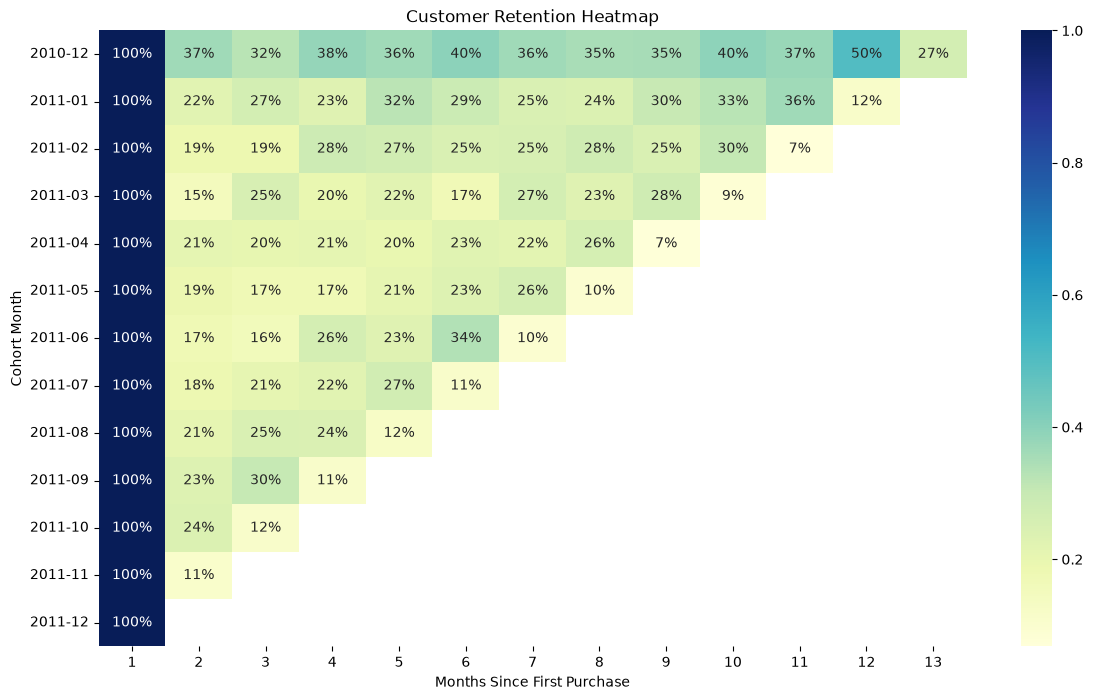

In [112]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14,8))

sns.heatmap(
    retention,
    annot=True,
    fmt=".0%",
    cmap="YlGnBu"
)

plt.title("Customer Retention Heatmap")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Cohort Month")

plt.show()

The company retains only a portion of new customers after their first purchase, as shown by the significant drop in Month 2 across every cohort. However, customer purchasing behavior is not strictly monthly. Many customers return after periods of inactivity, causing retention rates to increase in later months. This suggests that customers should not be considered permanently lost after missing a single month.

The consistently stronger performance of the December 2010 cohort may indicate the influence of holiday shopping, seasonal demand, or successful promotional campaigns that attracted higher-quality customers.

In [131]:
final_df = clean_df.dropna(subset=["CustomerID"]).copy()

final_df.to_csv("online_retail_final.csv", index=False)